![](img/banner.png)

# Mahalanobis Distance

**Mahmood Amintoosi, Fall 2026**

Computer Science Dept, Ferdowsi University of Mashhad

The covariance material follows chapter 2 of *Pattern Classification* by Duda, Hart, and Stork
({cite}`Duda2000`), whose notation we use; the geometric explanations are adapted from
[Vision Dummy](https://www.visiondummy.com/2014/04/geometric-interpretation-covariance-matrix/)
and from the [SAS blog on the Mahalanobis distance](https://blogs.sas.com/content/iml/2012/02/15/what-is-mahalanobis-distance.html).

**Learning objectives.** By the end you should be able to

1. say why Euclidean distance fails when features have different units or are correlated;
2. read a covariance matrix, and its eigenvalues and eigenvectors, as shape and orientation;
3. prove that $\operatorname{Cov}(W^{\top}(\mathbf{x}-\boldsymbol{\mu})) = W^{\top}\boldsymbol{\Sigma}W$;
4. build the whitening matrix $W = \Phi\Lambda^{-1/2}$ and show that whitening turns the
   Mahalanobis distance into a Euclidean one;
5. compute Mahalanobis distances and whitened coordinates with NumPy;
6. tell apart standardization, PCA and whitening;
7. place the Mahalanobis distance in the Gaussian discriminant of Bayesian decision theory.


## 1. Why Do We Need the Mahalanobis Distance?

In most applications the data are multivariate, the features are correlated and they are
measured on different scales. The **Euclidean distance**
($\|\mathbf{x}-\mathbf{y}\|_2$) assumes the opposite: uncorrelated features with the same
variance. If one feature is in metres and another in kilometres, the second one dominates the
sum by its numerical size alone. If the features are correlated, the cloud is an ellipsoid
rather than a sphere, and Euclidean distance ignores the orientation of that ellipsoid —
misleading results in classification and in clustering follow.

The **Mahalanobis distance** measures the distance between a point and a distribution,
normalised by the variance of each feature and by the correlations between them.

### Illustrative Example: Euclidean versus Mahalanobis

A two-dimensional Gaussian with high correlation, and two points at the same Euclidean distance
from its centre, one along the direction of large variance and one across it:


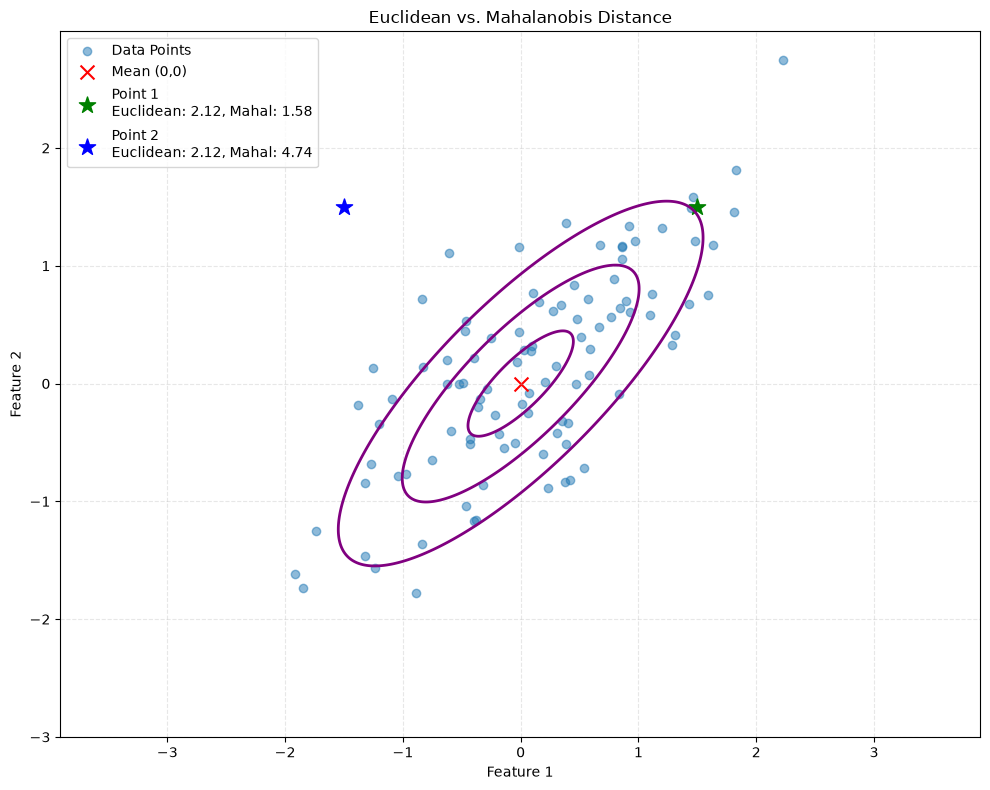

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import mahalanobis
from scipy.stats import multivariate_normal

# Set random seed for reproducibility
np.random.seed(42)

# Generate 2D Gaussian random points with high correlation
mean = [0, 0]
cov = [[1, 0.8], [0.8, 1]]  # Covariance matrix
points = np.random.multivariate_normal(mean, cov, 100)

# Select two points with the same Euclidean distance to the center but different locations
# Point 1 is along the direction of high variance
# Point 2 is along the direction of low variance
point1 = np.array([1.5, 1.5])
point2 = np.array([-1.5, 1.5])

# Compute Euclidean distances
center = np.array(mean)
euclidean_dist1 = np.linalg.norm(point1 - center)
euclidean_dist2 = np.linalg.norm(point2 - center)

# Compute Mahalanobis distances
inv_cov = np.linalg.inv(cov)
mahalanobis_dist1 = mahalanobis(point1, center, inv_cov)
mahalanobis_dist2 = mahalanobis(point2, center, inv_cov)

# Plot the data and points
plt.figure(figsize=(10, 8))
plt.scatter(points[:, 0], points[:, 1], alpha=0.5, label='Data Points')
plt.scatter(center[0], center[1], color='red', marker='x', s=100, label='Mean (0,0)')

# Highlight the two comparison points
plt.scatter(point1[0], point1[1], color='green', marker='*', s=150, 
            label=f'Point 1\nEuclidean: {euclidean_dist1:.2f}, Mahal: {mahalanobis_dist1:.2f}')
plt.scatter(point2[0], point2[1], color='blue', marker='*', s=150, 
            label=f'Point 2\nEuclidean: {euclidean_dist2:.2f}, Mahal: {mahalanobis_dist2:.2f}')

# Plot the probability contours
x, y = np.mgrid[-3:3:.01, -3:3:.01]
pos = np.dstack((x, y))
rv = multivariate_normal(mean, cov)
plt.contour(x, y, rv.pdf(pos), levels=3, colors='purple', linewidths=2)

plt.legend()
plt.title('Euclidean vs. Mahalanobis Distance')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.grid(True, linestyle='--', alpha=0.3)
plt.axis('equal')
plt.tight_layout()
plt.show()

*Observation:* Point 1 and Point 2 have the same Euclidean distance from the center, yet they lie in different "probability regions." Point 2 is in a direction of lower variance (orthogonal to the main correlation), making it statistically less likely (further in Mahalanobis distance) than Point 1.

---

## 2. Feature Scaling: A Case Study

### The Data

Three ballistic missiles, described by two features: range and speed.

| Missile | Range (km) | Speed (Mach) |
| :--- | :--- | :--- |
| **A. Khaybar Shikan** (target) | 1,450 | 5 |
| **B. Sejjil** | 2,000 | 10 |
| **C. Fatāh** | 1,400 | 14 |

<img src="img/Khaybar.jpg" width="230"> <img src="img/Sejjil.jpg" width="230"> <img src="img/Fattah.jpg" width="230">

Which of B and C is more similar to A?

### Raw Euclidean Distance

*  **Khaybar vs. Sejjil (B):** $\Delta\text{range} = 550$ km and $\Delta\text{speed} = 5$ Mach,
   so $D_{\text{raw}} = \sqrt{550^2 + 5^2} = 550.02$.
*  **Khaybar vs. Fatāh (C):** $\Delta\text{range} = 50$ km and $\Delta\text{speed} = 9$ Mach,
   so $D_{\text{raw}} = \sqrt{50^2 + 9^2} = 50.80$.

Fatāh looks ten times closer. The reason is arithmetic rather than similarity: the range column
takes values in the thousands, so 50 km is a small number next to 5 or 9 in the speed column.
The feature with the larger numerical range decides the answer.

### Standardized Distance

Divide each feature by its standard deviation, $z = (x-\mu)/\sigma$, so that both are measured
in standard deviations. For the three missiles

*  range: $\mu = 1616.7$ km, population $\sigma \approx 271.8$ km (sample $s \approx 332.9$ km);
*  speed: $\mu = 9.67$ Mach, population $\sigma \approx 3.68$ Mach (sample $s \approx 4.51$ Mach).

`StandardScaler` divides by the **population** standard deviation, by $N$ and not by $N-1$,
which is why the distances below use 271.8 and 3.68 while `pandas` prints 332.9 and 4.51. In
z-units A is $(-0.61, -1.27)$, B is $(1.41, 0.09)$ and C is $(-0.80, 1.18)$, so

*  Khaybar vs. Sejjil: $D_{\text{scaled}} = \sqrt{2.02^2 + 1.36^2} = 2.44$;
*  Khaybar vs. Fatāh: $D_{\text{scaled}} = \sqrt{0.18^2 + 2.44^2} = 2.45$.

| Comparison | Raw distance | Standardized distance |
| :--- | :--- | :--- |
| Khaybar vs. Sejjil | 550.02 | **2.44** |
| Khaybar vs. Fatāh | 50.80 | 2.45 |

The answer flips, by a hair: after standardization Sejjil is the nearer neighbour.

### Which Answer Is Right?

Neither. Standardizing says the two features deserve equal weight; the raw distance says one
kilometre counts as much as one Mach. Both are assumptions about the problem, not facts about
missiles, and the example is built so that they disagree. That is the lesson to keep: for any
method based on Euclidean distance — k-NN, k-means, the input layer of a network — the scaling
is part of the model, and it should be chosen rather than inherited from the units in which the
data happen to be stored.

### The Code

The next cell does the arithmetic: raw distances, then `StandardScaler`, then the same
Euclidean distance on the standardized columns.


In [2]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

# ============================================
# 1. REALISTIC IRANIAN MISSILE DATASET
# ============================================
data = {
    'Name': ['Khaybar Shikan', 'Sejjil', 'Fatāh'],
    'Range_km': [1450, 2000, 1400],
    'Speed_Mach': [5, 10, 14]
}

df = pd.DataFrame(data)
df.set_index('Name', inplace=True)

# Target: Compare Khaybar Shikan to Sejjil and Fatāh
target_name = 'Khaybar Shikan'
target = df.loc[target_name].values
other_names = ['Sejjil', 'Fatāh']
others = df.loc[other_names].values

# ============================================
# 2. RAW EUCLIDEAN DISTANCE (Unscaled)
# ============================================
raw_dist = np.linalg.norm(others - target, axis=1)

print("=== RAW EUCLIDEAN DISTANCE (Unscaled) ===")
for name, dist in zip(other_names, raw_dist):
    print(f"Distance to {name}: {dist:.2f}")

# ============================================
# 3. SCALED EUCLIDEAN DISTANCE (Standardized)
# ============================================
scaler = StandardScaler()
scaled_data = scaler.fit_transform(df[['Range_km', 'Speed_Mach']])
df_scaled = pd.DataFrame(scaled_data, index=df.index, columns=df.columns)

target_scaled = df_scaled.loc[target_name].values
others_scaled = df_scaled.loc[other_names].values

scaled_dist = np.linalg.norm(others_scaled - target_scaled, axis=1)

print("\n=== SCALED EUCLIDEAN DISTANCE (Normalized) ===")
for name, dist in zip(other_names, scaled_dist):
    print(f"Distance to {name}: {dist:.2f}")

# ============================================
# 4. SHOW THE FLIP
# ============================================
raw_winner = other_names[np.argmin(raw_dist)]
scaled_winner = other_names[np.argmin(scaled_dist)]

print("\n--- ANALYSIS ---")
print(f"Winner with raw distances: {raw_winner}")
print(f"Winner after standardization: {scaled_winner}")

# ============================================
# 5. SHOW STATISTICS
# ============================================
print("\n--- DATASET STATISTICS ---")
print(f"Range Std Dev: {df['Range_km'].std():.2f} km")
print(f"Speed Std Dev: {df['Speed_Mach'].std():.2f} Mach")


=== RAW EUCLIDEAN DISTANCE (Unscaled) ===
Distance to Sejjil: 550.02
Distance to Fatāh: 50.80

=== SCALED EUCLIDEAN DISTANCE (Normalized) ===
Distance to Sejjil: 2.44
Distance to Fatāh: 2.45

--- ANALYSIS ---
Winner with raw distances: Fatāh
Winner after standardization: Sejjil

--- DATASET STATISTICS ---
Range Std Dev: 332.92 km
Speed Std Dev: 4.51 Mach


The two printed statistics use different denominators: `df.std()` is the sample standard
deviation ($N-1$) while `StandardScaler` uses the population one ($N$). Both are reasonable;
the distances above come from the population version.


## 3. The Covariance Matrix

The **covariance matrix** is a square matrix that summarizes the variances and covariances of a set of random variables. For a dataset with $d$ features, the covariance matrix $\boldsymbol{\Sigma}$ is a $d \times d$ matrix defined as:

$$
\boldsymbol{\Sigma} = \begin{bmatrix}
\sigma_{11} & \sigma_{12} & \cdots & \sigma_{1d} \\
\sigma_{21} & \sigma_{22} & \cdots & \sigma_{2d} \\
\vdots & \vdots & \ddots & \vdots \\
\sigma_{d1} & \sigma_{d2} & \cdots & \sigma_{dd}
\end{bmatrix}
$$

Where:
*   $\sigma_{ii} = \operatorname{Var}(x_i)$: The variance of the $i$-th feature (diagonal elements).
*   $\sigma_{ij} = \operatorname{Cov}(x_i, x_j)$: The covariance between the $i$-th and $j$-th features (off-diagonal elements).

**Properties:**
1.  **Symmetric:** $\sigma_{ij} = \sigma_{ji}$, so $\boldsymbol{\Sigma} = \boldsymbol{\Sigma}^{\top}$.
2.  **Positive Semi-Definite:** All eigenvalues are non-negative ($\lambda_i \geq 0$).

---


## 4. Geometric Interpretation of the Covariance Matrix

The covariance matrix defines the **shape** and **orientation** of the data distribution in the feature space.

1.  **Eigenvectors (Directions):** The eigenvectors of $\boldsymbol{\Sigma}$ represent the principal axes of the data distribution. They indicate the directions of maximum variance.
2.  **Eigenvalues (Magnitudes):** The corresponding eigenvalues represent the magnitude of variance along these eigenvector directions.
3.  **Ellipsoid:** In 2D, the covariance matrix defines an ellipse. In $d$-dimensions, it defines a hyper-ellipsoid. The axes of this ellipsoid are aligned with the eigenvectors, and the lengths of the axes are proportional to the square roots of the eigenvalues.

---



## 5. Linear Transformations and Covariance

To fully understand Mahalanobis distance and whitening, we must understand how covariance changes under linear transformations. The following theorem provides the mathematical foundation for transforming data to a "whitened" space.

### Theorem 1 (Covariance Transformation Property)

Let $\mathbf{x} \in \mathbb{R}^d$ be a random vector with mean $\boldsymbol{\mu} = \mathbb{E}[\mathbf{x}]$ and covariance matrix $\boldsymbol{\Sigma} = \operatorname{Cov}(\mathbf{x})$. Let $W \in \mathbb{R}^{d \times d}$ be a constant transformation matrix. For a transformed random vector $\mathbf{y} = W^{\!\top}(\mathbf{x} - \boldsymbol{\mu})$, the covariance matrix of $\mathbf{y}$ is

$$
\boxed{\operatorname{Cov}(\mathbf{y}) = W^{\!\top}\boldsymbol{\Sigma}W}
$$

**Proof:**
We proceed by applying the definition of covariance and the linearity of expectation.

1.  **Mean of $\mathbf{y}$:**
    First, observe that the mean of the centered vector is zero:

    $$
    \begin{aligned}
    \mathbb{E}[\mathbf{y}]
    &= \mathbb{E}\bigl[W^{\!\top}(\mathbf{x} - \boldsymbol{\mu})\bigr] \\
    &= W^{\!\top}\bigl(\mathbb{E}[\mathbf{x}] - \boldsymbol{\mu}\bigr) \\
    &= W^{\!\top}(\boldsymbol{\mu} - \boldsymbol{\mu}) \\
    &= \mathbf{0}.
    \end{aligned}
    $$



2.  **Covariance of $\mathbf{y}$:**

    $$\text{Cov}(\mathbf{y}) = \mathbb{E}[(\mathbf{y} - \mathbb{E}[\mathbf{y}])(\mathbf{y} - \mathbb{E}[\mathbf{y}])^T]$$

    Since $\mathbb{E}[\mathbf{y}] = \mathbf{0}$, the covariance definition simplifies to $\operatorname{Cov}(\mathbf{y}) = \mathbb{E}[\mathbf{y}\mathbf{y}^{\!\top}]$.

    $$
    \begin{aligned}
    \operatorname{Cov}(\mathbf{y})
    &= \mathbb{E}\bigl[\mathbf{y}\,\mathbf{y}^{\!\top}\bigr] \\
    &= \mathbb{E}\Big[W^{\!\top}(\mathbf{x}-\boldsymbol{\mu})\,(\mathbf{x}-\boldsymbol{\mu})^{\!\top}W\Big].
    \end{aligned}
    $$

    By the linearity of the expectation operator, constant matrices $W^{\!\top}$ and $W$ can be pulled out of the expectation:

    $$
    \begin{aligned}
    \operatorname{Cov}(\mathbf{y})
    &= W^{\!\top}\;\mathbb{E}\Big[(\mathbf{x}-\boldsymbol{\mu})(\mathbf{x}-\boldsymbol{\mu})^{\!\top}\Big]\;W.
    \end{aligned}
    $$

    Recognizing that the term inside the expectation is exactly the definition of $\operatorname{Cov}(\mathbf{x}) = \boldsymbol{\Sigma}$:

    $$
    \operatorname{Cov}(\mathbf{y}) = W^{\!\top}\boldsymbol{\Sigma}W. \quad \square
    $$

**Remark (Whitening Application):**
This property is fundamental to **whitening**. By choosing $W$ such that $W^{\!\top}\boldsymbol{\Sigma}W = \mathbf{I}$, we transform the data into a space where features are uncorrelated and have unit variance. Section 6 constructs this $W$ from the eigendecomposition of $\boldsymbol{\Sigma}$.

## 6. Whitening Transformation

**Whitening** is a preprocessing step that turns the covariance matrix into the identity. The
transformed features are then uncorrelated and have unit variance.

![Figure 2.8 of Duda](img/Duda-Figure-2.8.png)

Figure 2.8 {cite}`Duda2000`: a linear transformation of the feature space maps an arbitrary
normal distribution to another normal distribution.

We want a matrix $W$ such that $\mathbf{y} = W^{\top}(\mathbf{x} - \boldsymbol{\mu})$ has
covariance $\mathbf{I}$. Section 5 gives $\operatorname{Cov}(\mathbf{y}) = W^{\top}\boldsymbol{\Sigma}W$,
and the eigendecomposition of Section 4, $\boldsymbol{\Sigma} = \Phi\Lambda\Phi^{\top}$, provides
$W = \Phi\Lambda^{-1/2}$. Checking it:

$$
\begin{aligned}
\operatorname{Cov}(\mathbf{y}) &= (\Phi \Lambda^{-1/2})^{\top} \boldsymbol{\Sigma} (\Phi \Lambda^{-1/2}) \\
&= \Lambda^{-1/2} \Phi^{\top} (\Phi \Lambda \Phi^{\top}) \Phi \Lambda^{-1/2} \\
&= \Lambda^{-1/2} \Lambda \Lambda^{-1/2} = \mathbf{I}.
\end{aligned}
$$

### Geometric Interpretation

1.  **Rotation** ($\Phi^{\top}$) aligns the data with the principal axes and removes the
    correlations.
2.  **Scaling** ($\Lambda^{-1/2}$) stretches or compresses each axis until its variance is 1.

The cloud becomes a sphere. In this space **the Euclidean distance is the Mahalanobis distance**
of the original space — Section 7 proves the identity, and the code below shows it numerically.


### The Same Two Points, Whitened

The code takes the correlated cloud and the two starred points of Section 1, applies
$W = \Phi\Lambda^{-1/2}$, and plots the data before and after. On the left the two points are at
the same Euclidean distance from the centre; on the right their Euclidean distances are their
Mahalanobis distances in the original space.


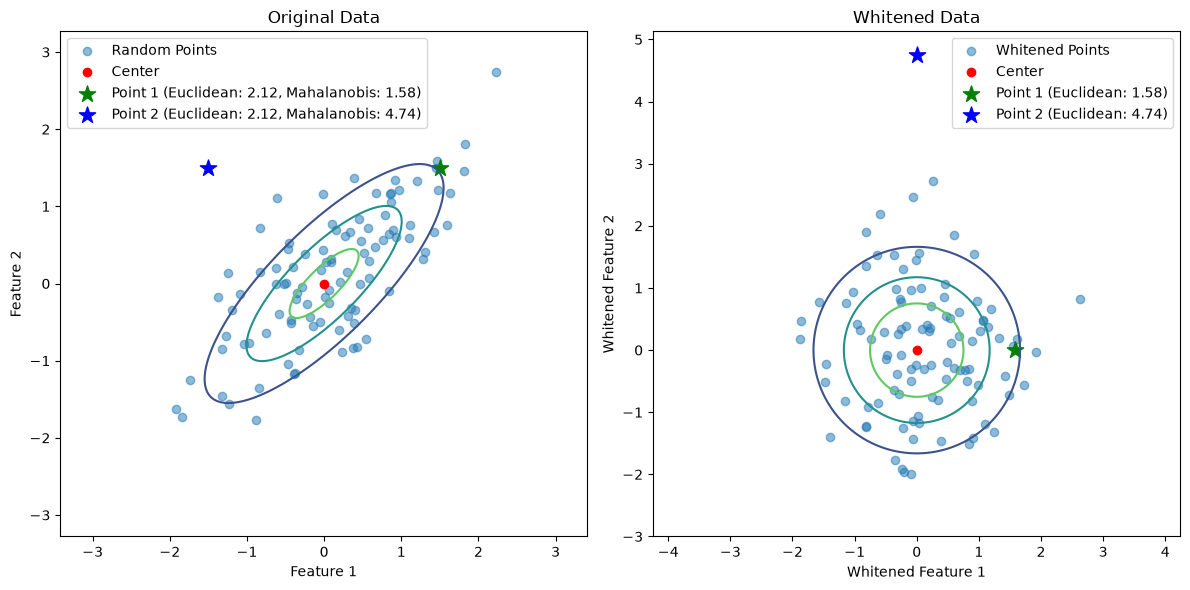

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import mahalanobis
from scipy.stats import multivariate_normal

# Generate 2D Gaussian random points
np.random.seed(42)
mean = [0, 0]
cov = [[1, 0.8], [0.8, 1]]  # Covariance matrix
points = np.random.multivariate_normal(mean, cov, 100)

# The center
center = mean

# Select two points with equal Euclidean distance to the center
point1 = np.array([1.5, 1.5])
point2 = np.array([-1.5, 1.5])

# Compute Euclidean distances
euclidean_dist1 = np.linalg.norm(point1 - center)
euclidean_dist2 = np.linalg.norm(point2 - center)

# Compute Mahalanobis distances
inv_cov = np.linalg.inv(cov)
mahalanobis_dist1 = mahalanobis(point1, center, inv_cov)
mahalanobis_dist2 = mahalanobis(point2, center, inv_cov)

# Whitening the data based on Duda's book
# Step 1: Compute the eigenvalues and eigenvectors of the covariance matrix
eigenvals, eigenvecs = np.linalg.eigh(cov)
idx = np.argsort(eigenvals)[::-1]
eigenvals = eigenvals[idx]
eigenvecs = eigenvecs[:, idx]

# Step 2: Construct the whitening matrix
D = np.diag(1.0 / np.sqrt(eigenvals))  # Diagonal matrix of inverse square roots of eigenvalues
W = np.dot(eigenvecs, D)  # Whitening matrix

# Step 3: Whiten the data
whitened_points = np.dot(points - center, W)  # Subtract mean and apply whitening transformation
whitened_point1 = np.dot(point1 - center, W)
whitened_point2 = np.dot(point2 - center, W)

# Compute Euclidean distances in the whitened space
whitened_euclidean_dist1 = np.linalg.norm(whitened_point1)
whitened_euclidean_dist2 = np.linalg.norm(whitened_point2)

# Plot the original and whitened data
plt.figure(figsize=(12, 6))

# Plot original data
plt.subplot(1, 2, 1)
plt.scatter(points[:, 0], points[:, 1], alpha=0.5, label='Random Points')
plt.scatter(center[0], center[1], color='red', label='Center')
plt.scatter(point1[0], point1[1], color='green', marker='*', s=150, label=f'Point 1 (Euclidean: {euclidean_dist1:.2f}, Mahalanobis: {mahalanobis_dist1:.2f})')
plt.scatter(point2[0], point2[1], color='blue', marker='*', s=150, label=f'Point 2 (Euclidean: {euclidean_dist2:.2f}, Mahalanobis: {mahalanobis_dist2:.2f})')

# Create a grid of points for the original data
x, y = np.mgrid[-3:3:.01, -3:3:.01]
pos = np.dstack((x, y))

# Compute the Gaussian distribution on the grid
rv = multivariate_normal(mean, cov)
plt.contour(x, y, rv.pdf(pos), levels=3, cmap='viridis')

plt.legend()
plt.title('Original Data')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.axis('equal')

# Plot whitened data
plt.subplot(1, 2, 2)
plt.scatter(whitened_points[:, 0], whitened_points[:, 1], alpha=0.5, label='Whitened Points')
plt.scatter(0, 0, color='red', label='Center')
plt.scatter(whitened_point1[0], whitened_point1[1], color='green', marker='*', s=150, label=f'Point 1 (Euclidean: {whitened_euclidean_dist1:.2f})')
plt.scatter(whitened_point2[0], whitened_point2[1], color='blue', marker='*', s=150, label=f'Point 2 (Euclidean: {whitened_euclidean_dist2:.2f})')

# Create a grid of points for the whitened data
x_whitened, y_whitened = np.mgrid[-3:3:.01, -3:3:.01]
pos_whitened = np.dstack((x_whitened, y_whitened))

# Compute the Gaussian distribution on the grid for whitened data
rv_whitened = multivariate_normal([0, 0], np.eye(2))  # Covariance matrix is identity after whitening
plt.contour(x_whitened, y_whitened, rv_whitened.pdf(pos_whitened), levels=3, cmap='viridis')

plt.legend()
plt.title('Whitened Data')
plt.xlabel('Whitened Feature 1')
plt.ylabel('Whitened Feature 2')
plt.axis('equal')

plt.tight_layout()
plt.show()

Both points are $2.12$ from the centre in the original Euclidean sense. Their Mahalanobis
distances are $1.58$ for the point along the principal axis and $4.74$ for the point across it;
after whitening the Euclidean distances are exactly those two numbers, in the same order. The
circle of constant radius in the right panel is an ellipse of constant Mahalanobis distance in
the left one.


## 7. The Mahalanobis Distance

In Section 6 we fixed the transformation and asked which covariance it produces. Here we ask the inverse question: which norm on the transformed coordinates reproduces the Mahalanobis distance of the original space?

The **Mahalanobis distance** is a measure of the distance between a point $\mathbf{x}$ and a distribution with mean $\boldsymbol{\mu}$ and covariance matrix $\mathbf{\Sigma}$. It is defined as:

$$D_M(\mathbf{x}, \boldsymbol{\mu}) = \sqrt{(\mathbf{x} - \boldsymbol{\mu})^T \mathbf{\Sigma}^{-1} (\mathbf{x} - \boldsymbol{\mu})}$$

This distance is central to many multivariate statistical methods, including Bayesian decision theory for classification, because it accounts for the underlying structure (variances and correlations) of the data.

### The Key Insight

The covariance transformation formula from Section 5 is **the fundamental mathematical foundation** for both whitening transformation and Mahalanobis distance.

**Recall the Mahalanobis distance:**

$$ D_M(\mathbf{x}) = \sqrt{(\mathbf{x} - \boldsymbol{\mu})^T \boldsymbol{\Sigma}^{-1} (\mathbf{x} - \boldsymbol{\mu})} $$

**Now consider the whitened space:**
If we define $\mathbf{y} = W^{\!\top}(\mathbf{x}-\boldsymbol{\mu})$ where $W$ makes $\operatorname{Cov}(\mathbf{y}) = \mathbf{I}$, then:

$$ \|\mathbf{y}\|_2 = \sqrt{\mathbf{y}^T \mathbf{y}} = \sqrt{(\mathbf{x} - \boldsymbol{\mu})^T W W^{\!\top} (\mathbf{x} - \boldsymbol{\mu})} $$

For this to equal the Mahalanobis distance, we need to show that $ W W^{\!\top} = \boldsymbol{\Sigma}^{-1} $.

**Proof:**

We are given: $ \boldsymbol{\Sigma} = \Phi \Lambda \Phi^{\top} $ and  $ W = \Phi \Lambda^{-1/2} $

We aim to show that  $W W^{\!\top} = \boldsymbol{\Sigma}^{-1}$


**Step 1: Compute $ W W^{\!\top} $**

Substitute $ W = \Phi \Lambda^{-1/2} $:

$$
W W^{\!\top}
= (\Phi \Lambda^{-1/2}) (\Phi \Lambda^{-1/2})^{\!\top}
$$

Now, transpose the second factor:

$$
(\Phi \Lambda^{-1/2})^{\!\top}
= (\Lambda^{-1/2})^{\!\top} \Phi^{\!\top}
$$

Since $ \Lambda $ is a diagonal matrix with positive eigenvalues (implying invertibility), $ \Lambda^{-1/2} $ is also diagonal and symmetric, so:

$$
(\Lambda^{-1/2})^{\!\top} = \Lambda^{-1/2}
$$

Thus,

$$
W W^{\!\top}
= \Phi \Lambda^{-1/2} (\Lambda^{-1/2}) \Phi^{\!\top}
= \Phi (\Lambda^{-1/2} \cdot \Lambda^{-1/2}) \Phi^{\!\top}
= \Phi \Lambda^{-1} \Phi^{\!\top}
$$


**Step 2: Compute $ \boldsymbol{\Sigma}^{-1} $ using the inverse of a diagonalized matrix**

We are given:

$$
\boldsymbol{\Sigma} = \Phi \Lambda \Phi^{\!\top}
$$

Since $ \Phi $ is an orthogonal matrix (i.e., $ \Phi^{\!\top} \Phi = I $), we know that:

$$
(\Phi \Lambda \Phi^{\!\top})^{-1}
= (\Phi^{\!\top})^{-1} \Lambda^{-1} \Phi^{-1}
$$

Because $ \Phi $ is orthogonal:
- $ \Phi^{-1} = \Phi^{\!\top} $
- So $ (\Phi^{\!\top})^{-1} = \Phi $

Therefore,

$$
(\Phi \Lambda \Phi^{\!\top})^{-1}
= \Phi \Lambda^{-1} \Phi^{\!\top}
$$


We have shown that:

$$
\boxed{W W^{\!\top} = \boldsymbol{\Sigma}^{-1}}
$$

**Key insight**: The orthogonality of $ \Phi $ allows us to simplify the inverse of $ \Phi \Lambda \Phi^{\!\top} $ elegantly, which is essential for establishing the result.



### Key Relationship

| Concept | Mathematical Expression | Purpose |
|---------|-----|---------|
| **Covariance Transformation** | $\operatorname{Cov}(\mathbf{y}) = W^{\!\top}\boldsymbol{\Sigma}W$ | Describes how covariance changes under linear transformation |
| **Whitening Matrix** | $W = \Phi \Lambda^{-1/2}$ | Transforms data to unit covariance |
| **Mahalanobis Distance** | $D_M = \sqrt{(\mathbf{x}-\boldsymbol{\mu})^T \boldsymbol{\Sigma}^{-1}(\mathbf{x}-\boldsymbol{\mu})}$ | Distance accounting for covariance structure |
| **Euclidean Distance (Whitened)** | $\|\mathbf{y}\|_2 = \sqrt{\mathbf{y}^T\mathbf{y}}$ | Distance after covariance normalization |
| **Key Equivalence** | $D_M(\mathbf{x}) = \|\mathbf{y}\|_2$ | Mahalanobis = Euclidean in whitened space |

---


## 8. Python Implementation, Step by Step

In [4]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import multivariate_normal

np.random.seed(42)

# ============================================================================
# 1. GENERATE CORRELATED DATA
# ============================================================================
print("=" * 70)
print("STEP 1: Generate Correlated Data (Original Space)")
print("=" * 70)

mean = np.array([1, 2])
cov_original = np.array([[4, 3], [3, 4]])  # Correlated data
n_samples = 500
data_original = np.random.multivariate_normal(mean, cov_original, n_samples)

print(f"Original Covariance:\n{cov_original}")

# ============================================================================
# 2. EIGEN DECOMPOSITION
# ============================================================================
print("\n" + "=" * 70)
print("STEP 2: Eigen Decomposition (Rotation + Scaling Factors)")
print("=" * 70)

eigenvalues, eigenvectors = np.linalg.eigh(cov_original)
idx = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[idx]
eigenvectors = eigenvectors[:, idx]
print(f"\nEigenvalues (λ): {eigenvalues}")
print(f"\nEigenvectors (Φ):")
print(eigenvectors)


STEP 1: Generate Correlated Data (Original Space)
Original Covariance:
[[4 3]
 [3 4]]

STEP 2: Eigen Decomposition (Rotation + Scaling Factors)

Eigenvalues (λ): [7. 1.]

Eigenvectors (Φ):
[[ 0.70710678 -0.70710678]
 [ 0.70710678  0.70710678]]


In [5]:

# ============================================================================
# 3. ROTATION ONLY (Phi^T: removes the correlation) 
# ============================================================================
print("\n" + "=" * 70)
print("STEP 3: Rotation Only")
print("=" * 70)

data_rotated = (data_original - mean) @ eigenvectors
cov_rotated = np.cov(data_rotated.T)

print(f"\nCovariance after Rotation (diagonal, up to sampling error):")
print(cov_rotated)
print(f"Off-diagonal before rotation: {cov_original[0, 1]:.4f}")
print(f"Off-diagonal after rotation: {cov_rotated[0, 1]:.4f}")

# ============================================================================
# 4. SCALING AFTER ROTATION (divide each axis by sqrt(lambda))
# ============================================================================
print("\n" + "=" * 70)
print("STEP 4: Scaling Only (Λ^(-1/2) normalizes variance)")
print("=" * 70)

scale_factors = 1.0 / np.sqrt(eigenvalues)
data_scaled = data_rotated @ np.diag(scale_factors)
cov_scaled = np.cov(data_scaled.T)

print(f"\nCovariance after Scaling (identity, up to sampling error):")
print(cov_scaled)



STEP 3: Rotation Only

Covariance after Rotation (diagonal, up to sampling error):
[[6.54609064 0.06692453]
 [0.06692453 0.98399756]]
Off-diagonal before rotation: 3.0000
Off-diagonal after rotation: 0.0669

STEP 4: Scaling Only (Λ^(-1/2) normalizes variance)

Covariance after Scaling (identity, up to sampling error):
[[0.93515581 0.02529509]
 [0.02529509 0.98399756]]


In [6]:

# ============================================================================
# 5. WHITENING: the same two steps as one matrix, W = Phi Lambda^(-1/2)
# ============================================================================
print("\n" + "=" * 70)
print("STEP 5:  Whitening (W = ΦΛ^(-1/2))")
print("=" * 70)

W = eigenvectors @ np.diag(scale_factors)
data_whitened = W.T @ (data_original - mean).T
data_whitened = data_whitened.T

print(f"\nWhitening Matrix (W = ΦΛ^(-1/2)):")
print(W)
print(f"\nCovariance after Whitening (W^T Σ W):")
print(np.cov(data_whitened.T))


STEP 5:  Whitening (W = ΦΛ^(-1/2))

Whitening Matrix (W = ΦΛ^(-1/2)):
[[ 0.26726124 -0.70710678]
 [ 0.26726124  0.70710678]]

Covariance after Whitening (W^T Σ W):
[[0.93515581 0.02529509]
 [0.02529509 0.98399756]]


The printed covariances are those of a *sample* of 500 points, not of the true
$\boldsymbol{\Sigma} = \begin{bmatrix} 4 & 3 \\ 3 & 4\end{bmatrix}$, and `np.cov` divides by
$n-1$. That is why the diagonal after rotation reads 6.55 and 0.98 instead of exactly 7 and 1,
and why after whitening it reads 0.94 and 0.98 instead of exactly 1: the transformation is
exact, the estimate of the covariance is not. Raise `n_samples` and the entries converge to the
identity.



STEP 6: Visualization of Transformation


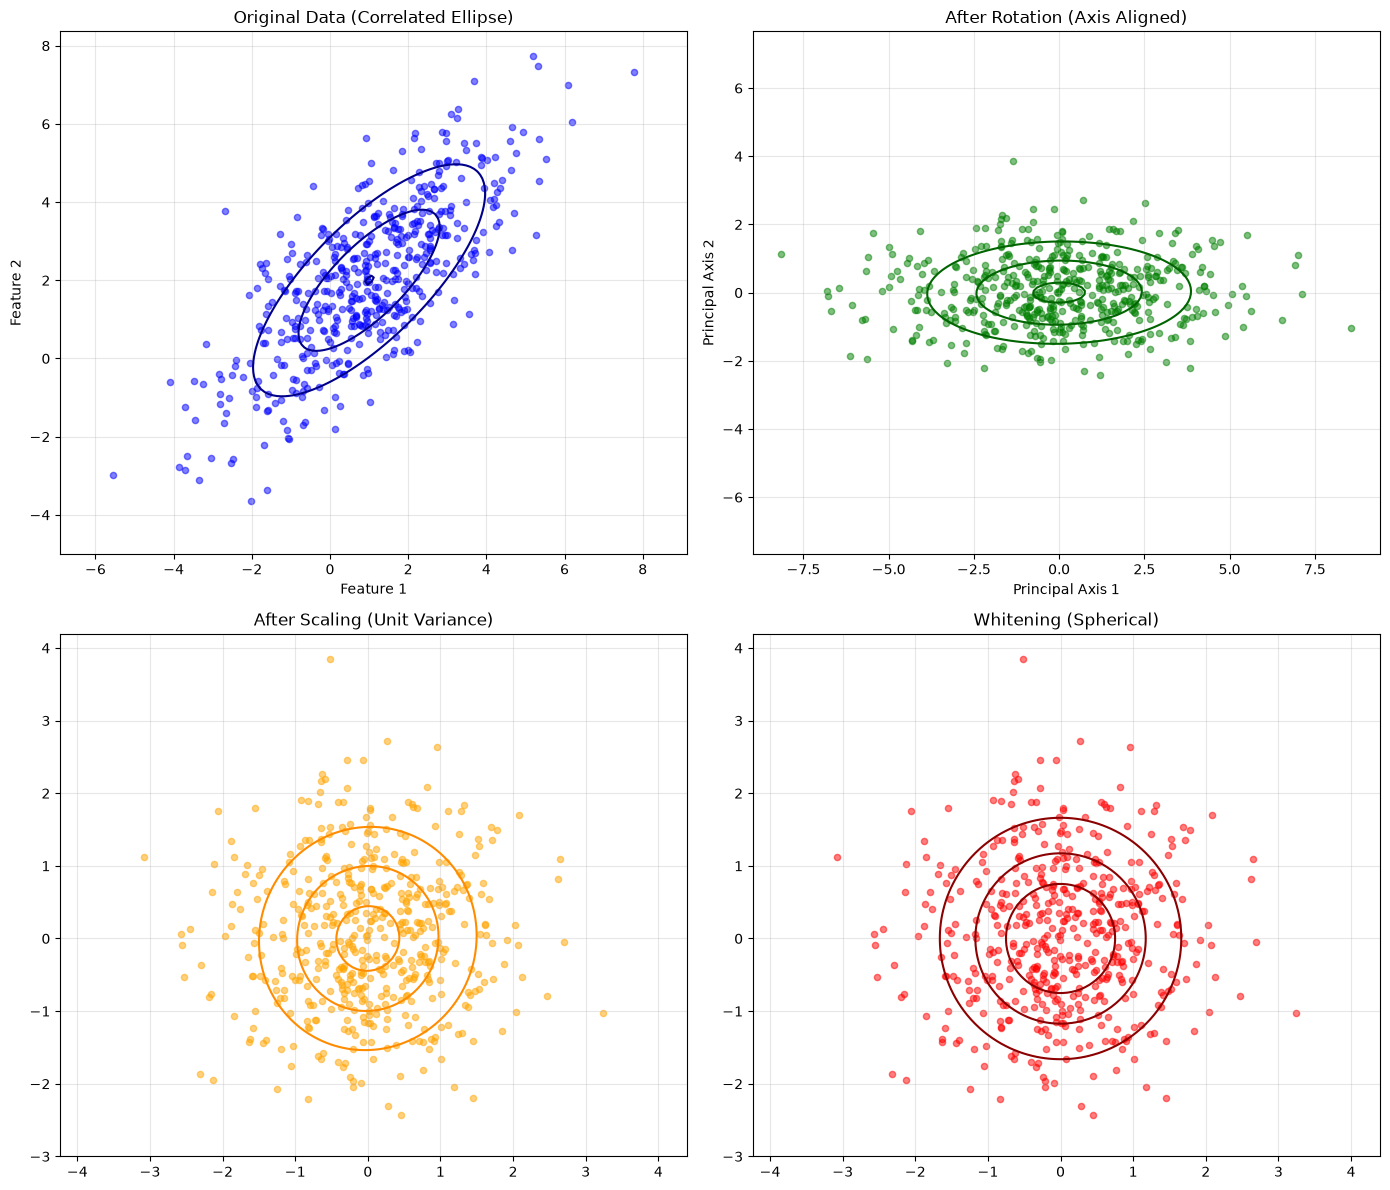

In [7]:

# ============================================================================
# 6. VISUALIZATION
# ============================================================================
print("\n" + "=" * 70)
print("STEP 6: Visualization of Transformation")
print("=" * 70)

fig, axes = plt.subplots(2, 2, figsize=(14, 12))

# Original Data
axes[0, 0].scatter(data_original[:, 0], data_original[:, 1], alpha=0.5, s=20, color='blue', label='Original')
pos = np.dstack(np.mgrid[-5:5:100j, -5:5:100j])
axes[0, 0].contour(pos[:,:,0], pos[:,:,1], multivariate_normal(mean, cov_original).pdf(pos), levels=3, colors='darkblue')
axes[0, 0].set_title('Original Data (Correlated Ellipse)')
axes[0, 0].set_xlabel('Feature 1'); axes[0, 0].set_ylabel('Feature 2')
axes[0, 0].grid(True, alpha=0.3); axes[0, 0].axis('equal')

# After Rotation
axes[0, 1].scatter(data_rotated[:, 0], data_rotated[:, 1], alpha=0.5, s=20, color='green', label='Rotated')
pos = np.dstack(np.mgrid[-5:5:100j, -5:5:100j])
axes[0, 1].contour(pos[:,:,0], pos[:,:,1], multivariate_normal(np.zeros(2), cov_rotated).pdf(pos), levels=3, colors='darkgreen')
axes[0, 1].set_title('After Rotation (Axis Aligned)')
axes[0, 1].set_xlabel('Principal Axis 1'); axes[0, 1].set_ylabel('Principal Axis 2')
axes[0, 1].grid(True, alpha=0.3); axes[0, 1].axis('equal')

# After Scaling
axes[1, 0].scatter(data_scaled[:, 0], data_scaled[:, 1], alpha=0.5, s=20, color='orange', label='Scaled')
pos = np.dstack(np.mgrid[-3:3:100j, -3:3:100j])
axes[1, 0].contour(pos[:,:,0], pos[:,:,1], multivariate_normal(np.zeros(2), cov_scaled).pdf(pos), levels=3, colors='darkorange')
axes[1, 0].set_title('After Scaling (Unit Variance)')
axes[1, 0].grid(True, alpha=0.3); axes[1, 0].axis('equal')

# Combined Whitening
axes[1, 1].scatter(data_whitened[:, 0], data_whitened[:, 1], alpha=0.5, s=20, color='red', label='Whitened')
pos = np.dstack(np.mgrid[-3:3:100j, -3:3:100j])
axes[1, 1].contour(pos[:,:,0], pos[:,:,1], multivariate_normal(np.zeros(2), np.eye(2)).pdf(pos), levels=3, colors='darkred')
axes[1, 1].set_title('Whitening (Spherical)')
axes[1, 1].grid(True, alpha=0.3); axes[1, 1].axis('equal')

plt.tight_layout()
plt.show()


In [8]:

# ============================================================================
# 7. MAHALANOBIS DISTANCE VERIFICATION
# ============================================================================
print("\n" + "=" * 70)
print("STEP 7: Mahalanobis Distance = Euclidean in Whitened Space")
print("=" * 70)

test_point = np.array([4, 4])
inv_cov = np.linalg.inv(cov_original)
mahalanobis_dist = np.sqrt((test_point - mean) @ inv_cov @ (test_point - mean))
test_point_whitened = W.T @ (test_point - mean)
euclidean_dist_whitened = np.linalg.norm(test_point_whitened)

print(f"\nTest Point: {test_point}")
print(f"Mahalanobis Distance (Original Space): {mahalanobis_dist:.4f}")
print(f"Euclidean Distance (Whitened Space): {euclidean_dist_whitened:.4f}")
print("\nMahalanobis distance and whitened Euclidean distance agree.")


STEP 7: Mahalanobis Distance = Euclidean in Whitened Space

Test Point: [4 4]
Mahalanobis Distance (Original Space): 1.5119
Euclidean Distance (Whitened Space): 1.5119

Mahalanobis distance and whitened Euclidean distance agree.


## 9. The Covariance Matrix in Bayesian Decision Theory

The Gaussian class-conditional density of the
[Bayesian decision theory](Bayesian-Decision-Theory.ipynb) page is

$$
p(\mathbf{x} \mid \omega_i) = \frac{1}{(2\pi)^{d/2}|\boldsymbol{\Sigma}_i|^{1/2}}
\exp\left(-\frac{1}{2}(\mathbf{x} - \boldsymbol{\mu}_i)^{\top}
\boldsymbol{\Sigma}_i^{-1} (\mathbf{x} - \boldsymbol{\mu}_i)\right),
$$

where $\boldsymbol{\mu}_i$ and $\boldsymbol{\Sigma}_i$ are estimated per class by maximum
likelihood ([MLE page](MLE-Introduction.ipynb)).

*  The exponent is exactly half the **squared Mahalanobis distance** from $\mathbf{x}$ to
   $\boldsymbol{\mu}_i$.
*  A common covariance, $\boldsymbol{\Sigma}_i = \boldsymbol{\Sigma}$ for all $i$, makes the
   log-discriminant linear, and the boundaries are hyperplanes: that is LDA.
*  A separate covariance per class leaves a quadratic term and gives QDA.
*  If $\hat{\boldsymbol{\Sigma}}_i$ is singular — too few samples per class compared with
   $d$ — the density, and with it the Mahalanobis distance, is undefined until the estimate is
   regularised.

So the Mahalanobis distance is not a distance formula added to classification: it *is* the
geometry of the Gaussian classifier.


## 10. Mahalanobis Distance and Its Role

For one feature, the z-score measures how many standard deviations a value is from the mean.
The Mahalanobis distance is the same idea for $d$ features:

$$
z^2 = \frac{(x-\mu)^2}{\sigma^2}
\qquad\longrightarrow\qquad
D_M^2 = (\mathbf{x}-\boldsymbol{\mu})^{\top}\boldsymbol{\Sigma}^{-1}(\mathbf{x}-\boldsymbol{\mu}).
$$

The role of $\sigma^2$ is taken by the covariance matrix, so $\boldsymbol{\Sigma}^{-1}$ does two
things at once: it scales each feature by its variance and it rotates the space to remove the
correlations. Geometrically, $D_M$ counts how many "standard deviations" a point is from the
centre of an ellipsoidal cloud, measuring the distance along the stretched and rotated axes of
that ellipsoid.

### From a Distance to a Test

For data drawn from $\mathcal{N}(\boldsymbol{\mu}, \boldsymbol{\Sigma})$ the squared Mahalanobis
distance is a $\chi^2$ variable with $d$ degrees of freedom, $D_M^2 \sim \chi^2_d$. The distance
therefore converts into a probability statement, which is what an anomaly detector needs: the
95% and 99% quantiles of $\chi^2_2$ are 5.99 and 9.21, so a point with $D_M^2$ beyond them lies
outside the corresponding probability contour of the ellipse. This is the multivariate version
of the "more than two standard deviations away" rule, and it is the most common practical use
of the distance.


## 11. Standardization, PCA and Whitening

All three transformations start from the same statistics and are easy to confuse. In terms of
the eigendecomposition $\boldsymbol{\Sigma} = \Phi\Lambda\Phi^{\top}$:

*  **Standardization** divides each feature by its own standard deviation. It changes the
   diagonal of the covariance to one but leaves the off-diagonal correlations in place.
*  **PCA** rotates to the principal axes, $\mathbf{z} = \Phi^{\top}(\mathbf{x} - \boldsymbol{\mu})$,
   and has covariance $\Lambda$: the correlations are gone, the variances $\lambda_i$ remain.
*  **Whitening** rotates and then scales,
   $\mathbf{y} = \Lambda^{-1/2}\Phi^{\top}(\mathbf{x} - \boldsymbol{\mu}) = \Lambda^{-1/2}\mathbf{z}$,
   and has covariance $\mathbf{I}$.

| Property | Standardization | PCA | Whitening |
| :--- | :--- | :--- | :--- |
| Goal | comparable units | reduce dimension, keep variance | unit variance and no correlation |
| Transformation | $x_i' = (x_i-\mu_i)/\sigma_i$ | $\Phi^{\top}(\mathbf{x}-\boldsymbol{\mu})$ | $\Lambda^{-1/2}\Phi^{\top}(\mathbf{x}-\boldsymbol{\mu})$ |
| Covariance afterwards | correlations kept | diagonal, $\Lambda$ | identity, $\mathbf{I}$ |
| Shape of the cloud | same ellipse | axis-aligned ellipse | sphere |
| Euclidean $=$ Mahalanobis? | no | no | yes |
| Loss of information | none | if $k<d$ components are kept | none at full rank |

The one that makes Euclidean distance meaningful is whitening: after standardization the
features still have different variances along the correlated directions, and after PCA the
axes still have the variances $\lambda_i$. Only when every direction has variance 1 does a
Euclidean ball become a contour of constant probability density.

### Demonstration: PCA versus Whitening

The next cell applies both transformations to the same cloud and prints the three distances of
one test point.



COMPARISON: Original → PCA → Whitening


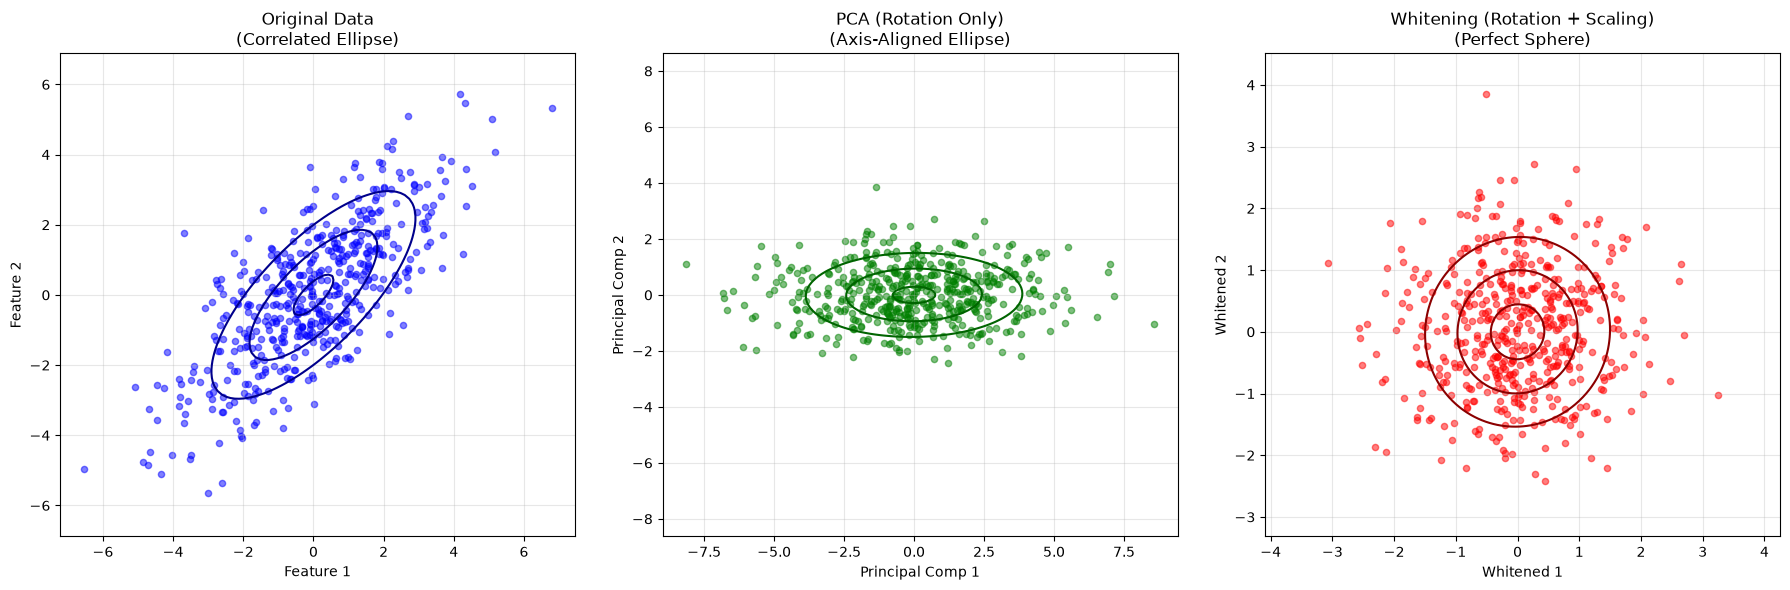


Distance Metrics for a Test Point

Test Point: [2. 1.]
Mahalanobis Distance (Original): 1.0690
Euclidean Distance (PCA Space):  2.2361
Euclidean Distance (White Space): 1.0690

Conclusion: only whitening keeps the Euclidean distance equal to the Mahalanobis one.


In [9]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import multivariate_normal

np.random.seed(42)

# ============================================================================
# 1. GENERATE CORRELATED DATA
# ============================================================================
mean = np.array([0, 0])
cov_original = np.array([[4, 3], [3, 4]])  # Correlated data
n_samples = 500
data_original = np.random.multivariate_normal(mean, cov_original, n_samples)
# print(f"Original data shape: {data_original.shape}")  # (500, 2)

# ============================================================================
# 2. PREPARE TRANSFORMATIONS
# ============================================================================
eigenvalues, eigenvectors = np.linalg.eigh(cov_original)
idx = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[idx]
eigenvectors = eigenvectors[:, idx]

# PCA Transformation (Rotation Only)
# Correct: Keep shape (n_samples, n_features)
data_pca = (data_original - mean) @ eigenvectors

# Whitening Transformation (Rotation + Scaling)
scale_factors = 1.0 / np.sqrt(eigenvalues)
data_whitened = data_pca @ np.diag(scale_factors)

# print(f"PCA data shape: {data_pca.shape}")  # (500, 2)
# print(f"Whitened data shape: {data_whitened.shape}")  # (500, 2)

# ============================================================================
# 3. COMPUTE COVARIANCES
# ============================================================================
cov_original_computed = np.cov(data_original, rowvar=False)
cov_pca = np.cov(data_pca, rowvar=False)
cov_white = np.cov(data_whitened, rowvar=False)

# print(f"\nCovariance shapes:")
# print(f"Original: {cov_original_computed.shape}")  # (2, 2)
# print(f"PCA: {cov_pca.shape}")  # (2, 2)
# print(f"Whitened: {cov_white.shape}")  # (2, 2)

# ============================================================================
# 4. VISUALIZATION
# ============================================================================
print("\n" + "=" * 70)
print("COMPARISON: Original → PCA → Whitening")
print("=" * 70)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# --- Plot 1: Original ---
axes[0].scatter(data_original[:, 0], data_original[:, 1], alpha=0.5, s=20, color='blue')
x, y = np.mgrid[-6:6:100j, -6:6:100j]
pos = np.dstack((x, y))
axes[0].contour(x, y, multivariate_normal(mean, cov_original_computed).pdf(pos), levels=3, colors='darkblue')
axes[0].set_title('Original Data\n(Correlated Ellipse)')
axes[0].set_xlabel('Feature 1'); axes[0].set_ylabel('Feature 2')
axes[0].grid(True, alpha=0.3); axes[0].axis('equal')

# --- Plot 2: PCA (Rotation Only) ---
axes[1].scatter(data_pca[:, 0], data_pca[:, 1], alpha=0.5, s=20, color='green')
x, y = np.mgrid[-5:5:100j, -5:5:100j]
pos = np.dstack((x, y))
axes[1].contour(x, y, multivariate_normal(np.zeros(2), cov_pca).pdf(pos), levels=3, colors='darkgreen')
axes[1].set_title('PCA (Rotation Only)\n(Axis-Aligned Ellipse)')
axes[1].set_xlabel('Principal Comp 1'); axes[1].set_ylabel('Principal Comp 2')
axes[1].grid(True, alpha=0.3); axes[1].axis('equal')

# --- Plot 3: Whitening (Rotation + Scaling) ---
axes[2].scatter(data_whitened[:, 0], data_whitened[:, 1], alpha=0.5, s=20, color='red')
x, y = np.mgrid[-3:3:100j, -3:3:100j]
pos = np.dstack((x, y))
axes[2].contour(x, y, multivariate_normal(np.zeros(2), cov_white).pdf(pos), levels=3, colors='darkred')
axes[2].set_title('Whitening (Rotation + Scaling)\n(Perfect Sphere)')
axes[2].set_xlabel('Whitened 1'); axes[2].set_ylabel('Whitened 2')
axes[2].grid(True, alpha=0.3); axes[2].axis('equal')

plt.tight_layout()
plt.show()

# ============================================================================
# 5. DISTANCE COMPARISON
# ============================================================================
print("\n" + "=" * 70)
print("Distance Metrics for a Test Point")
print("=" * 70)

test_point = np.array([2.0, 1.0])
inv_cov = np.linalg.inv(cov_original)
mahal_dist = np.sqrt((test_point - mean) @ inv_cov @ (test_point - mean))

# Euclidean in PCA space
test_pca = (test_point - mean) @ eigenvectors
euclid_pca = np.linalg.norm(test_pca)

# Euclidean in Whitened space
test_white = test_pca @ np.diag(scale_factors)
euclid_white = np.linalg.norm(test_white)

print(f"\nTest Point: {test_point}")
print(f"Mahalanobis Distance (Original): {mahal_dist:.4f}")
print(f"Euclidean Distance (PCA Space):  {euclid_pca:.4f}")
print(f"Euclidean Distance (White Space): {euclid_white:.4f}")

print("\nConclusion: only whitening keeps the Euclidean distance equal to the Mahalanobis one.")


### Why This Matters for Mahalanobis Distance

1.  **PCA** aligns the data with the principal axes but **preserves the different variances** along those axes. If you measure Euclidean distance in PCA space, a point 2 units away along a high-variance axis is treated the same as a point 2 units away along a low-variance axis. This distorts the statistical probability.
2.  **Whitening** normalizes the variances. In this space, **1 unit equals 1 standard deviation** in every direction. Therefore, Euclidean distance in whitened space correctly represents the statistical "surprise" (Mahalanobis distance) of a point.


## Conclusion

The **Mahalanobis distance** is the natural generalization of the z-score to several
dimensions. Through the covariance matrix it accounts for the scale of each feature and for
the correlation between features, which Euclidean distance cannot do. It is used for

*  **anomaly detection**: flagging points that are statistically unlikely, against a $\chi^2$
   quantile;
*  **classification**: it is the exponent of the Gaussian discriminant of
   [Bayesian decision theory](Bayesian-Decision-Theory.ipynb), whose parameters come from the
   [MLE page](MLE-Introduction.ipynb);
*  **preprocessing**: whitening, after which Euclidean tools become valid.

## Key Takeaways

*  **Euclidean distance** assumes spherical data; **Mahalanobis distance** assumes elliptical
   data.
*  The **covariance matrix** $\boldsymbol{\Sigma}$ carries the shape, the scale and the
   orientation of the distribution.
*  **Whitening** maps $\boldsymbol{\Sigma}$ to $\mathbf{I}$ and turns the cloud into a sphere.
*  If $\mathbf{y} = W^{\top}(\mathbf{x}-\boldsymbol{\mu})$ then
   $\operatorname{Cov}(\mathbf{y}) = W^{\top}\boldsymbol{\Sigma}W$; for $W = \Phi\Lambda^{-1/2}$
   this is $\mathbf{I}$.
*  In the whitened space Euclidean distance equals Mahalanobis distance; per-feature
   standardization does not achieve this, because it keeps the correlations.

## References

{cite}`Duda2000`

Duda, R. O., Hart, P. E., & Stork, D. G. (2000). *Pattern Classification* (2nd ed.).
Wiley-Interscience, chapter 2.
